# Sales Forecasting & Business Intelligence Platform

## Dataset & Business Understanding

### Dataset

UCI Machine Learning Repository — Online Retail II.

The dataset contains transaction-level records from a UK-based
online retailer covering approximately two years.

### Business Objective

The primary objective of this project is to analyze historical
retail transactions and forecast future revenue for:

- 30 days
- 60 days
- 90 days

The project will support business questions related to:

- Revenue trends
- Product performance
- Geographic performance
- Sales seasonality
- Customer activity
- Revenue forecasting
- Forecast uncertainty

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from ml.config import (
    RAW_RETAIL_FILE,
)

from ml.data.loader import (
    get_excel_sheets,
    load_retail_data,
)


pd.set_option(
    "display.max_columns",
    None,
)

pd.set_option(
    "display.float_format",
    "{:,.2f}".format,
)

In [3]:
print("Dataset:")

print(RAW_RETAIL_FILE)

print(
    "\nExists:",
    RAW_RETAIL_FILE.exists(),
)

Dataset:
D:\Research_Project\sales-forecasting-platform\data\raw\online_retail_II.xlsx

Exists: True


In [4]:
#Inspect Excel sheets
sheet_names = (
    get_excel_sheets()
)

print("Workbook sheets:")

for sheet in sheet_names:

    print(
        f"- {sheet}"
    )

Workbook sheets:
- Year 2009-2010
- Year 2010-2011


In [5]:
#Load raw dataset
df = load_retail_data()
df.head()
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France,Year 2010-2011
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France,Year 2010-2011
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France,Year 2010-2011
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France,Year 2010-2011
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,"12,680.00",France,Year 2010-2011


In [6]:
#Dataset shape
rows, columns = df.shape

print(
    f"Rows    : {rows:,}"
)

print(
    f"Columns : {columns:,}"
)

Rows    : 1,067,371
Columns : 9


In [7]:
#check distribution by sheet
df["source_sheet"].value_counts()


source_sheet
Year 2010-2011    541910
Year 2009-2010    525461
Name: count, dtype: int64

In [8]:
#Columns
for index, column in enumerate(
    df.columns,
    start=1,
):

    print(
        f"{index:02d}. {column}"
    )

01. Invoice
02. StockCode
03. Description
04. Quantity
05. InvoiceDate
06. Price
07. Customer ID
08. Country
09. source_sheet


In [11]:
#standardize column names
working_df = df.copy()
working_df.columns = (
    working_df.columns
    .str.strip()
    .str.lower()
    .str.replace(
        " ",
        "_",
        regex=False,
    )
)
working_df.columns.tolist()

['invoice',
 'stockcode',
 'description',
 'quantity',
 'invoicedate',
 'price',
 'customer_id',
 'country',
 'source_sheet']

In [12]:
#rename schema standard
column_mapping = {
    "invoice": "invoice_no",
    "invoiceno": "invoice_no",

    "stockcode": "stock_code",

    "description": "description",

    "quantity": "quantity",

    "invoicedate": "invoice_date",

    "price": "unit_price",
    "unitprice": "unit_price",

    "customer_id": "customer_id",
    "customerid": "customer_id",

    "country": "country",
}
working_df = (
    working_df.rename(
        columns=column_mapping
    )
)
working_df.columns.tolist()

['invoice_no',
 'stock_code',
 'description',
 'quantity',
 'invoice_date',
 'unit_price',
 'customer_id',
 'country',
 'source_sheet']

In [13]:
#required columns
required_columns = {
    "invoice_no",
    "stock_code",
    "description",
    "quantity",
    "invoice_date",
    "unit_price",
    "customer_id",
    "country",
}


missing_columns = (
    required_columns
    - set(working_df.columns)
)


print(
    "Missing required columns:",
    missing_columns,
)

Missing required columns: set()


In [14]:
#Data Types
working_df.info()
working_df.dtypes


<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice_no    1067371 non-null  object        
 1   stock_code    1067371 non-null  object        
 2   description   1062989 non-null  object        
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   unit_price    1067371 non-null  float64       
 6   customer_id   824364 non-null   float64       
 7   country       1067371 non-null  str           
 8   source_sheet  1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(2)
memory usage: 73.3+ MB


invoice_no              object
stock_code              object
description             object
quantity                 int64
invoice_date    datetime64[us]
unit_price             float64
customer_id            float64
country                    str
source_sheet               str
dtype: object

In [15]:
#Missing Values
missing_report = pd.DataFrame({
    "missing_count":
        working_df.isna().sum(),

    "missing_percent":
        working_df.isna().mean()
        * 100,
})

missing_report = (
    missing_report
    .sort_values(
        "missing_percent",
        ascending=False,
    )
)

missing_report

,missing_count,missing_percent
customer_id,243007,22.77
description,4382,0.41
invoice_no,0,0.00
quantity,0,0.00
stock_code,0,0.00
invoice_date,0,0.00
unit_price,0,0.00
country,0,0.00
source_sheet,0,0.00


In [16]:
#Duplicate Rows
duplicate_count = (
    working_df
    .duplicated()
    .sum()
)

duplicate_percentage = (
    duplicate_count
    / len(working_df)
    * 100
)


print(
    f"Duplicate rows: "
    f"{duplicate_count:,}"
)

print(
    f"Duplicate percentage: "
    f"{duplicate_percentage:.2f}%"
)

Duplicate rows: 12,133
Duplicate percentage: 1.14%


In [17]:
#Convert Date cho analysis
working_df[
    "invoice_date"
] = pd.to_datetime(
    working_df["invoice_date"],
    errors="coerce",
)
working_df[
    "invoice_date"
].isna().sum()

np.int64(0)

In [18]:
#Date Range
min_date = (
    working_df[
        "invoice_date"
    ].min()
)

max_date = (
    working_df[
        "invoice_date"
    ].max()
)


print(
    "Start:",
    min_date,
)

print(
    "End:",
    max_date,
)

Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00


In [19]:
#Historical Coverage
history_days = (
    max_date - min_date
).days

history_years = (
    history_days / 365.25
)

print(
    f"Historical coverage: "
    f"{history_days:,} days"
)

print(
    f"Historical coverage: "
    f"{history_years:.2f} years"
)

Historical coverage: 738 days
Historical coverage: 2.02 years


In [20]:
#Quantity Analysis
working_df[
    "quantity"
].describe()

negative_quantity = (
    working_df[
        "quantity"
    ] < 0
).sum()

zero_quantity = (
    working_df[
        "quantity"
    ] == 0
).sum()


print(
    f"Negative quantity: "
    f"{negative_quantity:,}"
)

print(
    f"Zero quantity: "
    f"{zero_quantity:,}"
)

Negative quantity: 22,950
Zero quantity: 0


In [21]:
#Price Analysis
working_df[
    "unit_price"

].describe()

negative_price = (
    working_df[
        "unit_price"
    ] < 0
).sum()

zero_price = (
    working_df[
        "unit_price"
    ] == 0
).sum()


print(
    f"Negative price: "
    f"{negative_price:,}"
)

print(
    f"Zero price: "
    f"{zero_price:,}"
)

Negative price: 5
Zero price: 6,202


In [22]:
#Cancellation Detection
invoice_as_text = (
    working_df[
        "invoice_no"
    ]
    .astype(str)
    .str.strip()
)
#Cancellation flag
working_df[
    "is_cancelled"
] = (
    invoice_as_text
    .str.upper()
    .str.startswith("C")
)
#statistic
cancellation_count = (
    working_df[
        "is_cancelled"
    ].sum()
)

cancellation_rate = (
    working_df[
        "is_cancelled"
    ].mean()
    * 100
)


print(
    f"Cancelled rows: "
    f"{cancellation_count:,}"
)

print(
    f"Cancellation rate: "
    f"{cancellation_rate:.2f}%"
)

Cancelled rows: 19,494
Cancellation rate: 1.83%


In [23]:
#show cancellation samples
working_df[
    working_df[
        "is_cancelled"
    ]
].head(20)

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_cancelled
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010,True
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,"16,321.00",Australia,Year 2009-2010,True
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,"16,321.00",Australia,Year 2009-2010,True
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,"16,321.00",Australia,Year 2009-2010,True
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010,True
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia,Year 2009-2010,True
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia,Year 2009-2010,True
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,"16,321.00",Australia,Year 2009-2010,True
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010,True
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,"17,592.00",United Kingdom,Year 2009-2010,True


In [24]:
#Temporary Revenue
working_df[
    "line_revenue"
] = (
    working_df["quantity"]
    * working_df["unit_price"]
)

working_df[
    "line_revenue"
].describe()

count   1,067,371.00
mean           18.07
std           292.42
min      -168,469.60
25%             3.75
50%             9.90
75%            17.70
max       168,469.60
Name: line_revenue, dtype: float64

In [25]:
#Revenue can be negative
negative_revenue = (
    working_df[
        "line_revenue"
    ] < 0
).sum()

print(
    f"Negative revenue rows: "
    f"{negative_revenue:,}"
)

Negative revenue rows: 19,498


In [26]:
#Transaction Count
transaction_rows = len(
    working_df
)

unique_invoices = (
    working_df[
        "invoice_no"
    ]
    .nunique()
)


print(
    f"Transaction rows: "
    f"{transaction_rows:,}"
)

print(
    f"Unique invoices: "
    f"{unique_invoices:,}"
)

Transaction rows: 1,067,371
Unique invoices: 53,628


In [27]:
#Unique Products
unique_products = (
    working_df[
        "stock_code"
    ]
    .nunique()
)

print(
    f"Unique stock codes: "
    f"{unique_products:,}"
)

Unique stock codes: 5,305


In [28]:
#Unique Customers
unique_customers = (
    working_df[
        "customer_id"
    ]
    .nunique(
        dropna=True
    )
)

print(
    f"Known customers: "
    f"{unique_customers:,}"
)

Known customers: 5,942


In [29]:
#Countries
country_count = (
    working_df[
        "country"
    ]
    .nunique()
)

print(
    f"Countries: "
    f"{country_count:,}"
)

Countries: 43


In [30]:
working_df[
    "country"
].value_counts().head(10)

country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64

In [31]:
#Revenue by Country
country_revenue = (
    working_df
    .groupby(
        "country"
    )["line_revenue"]
    .sum()
    .sort_values(
        ascending=False
    )
)

country_revenue.head(10)

country
United Kingdom   16,382,583.90
EIRE                615,519.55
Netherlands         548,524.95
Germany             417,988.56
France              328,191.80
Australia           167,129.07
Switzerland          99,728.76
Spain                91,859.48
Sweden               87,809.42
Denmark              65,741.09
Name: line_revenue, dtype: float64

In [32]:
#Daily raw revenue
working_df[
    "invoice_day"
] = (
    working_df[
        "invoice_date"
    ]
    .dt.floor("D")
)
daily_raw_revenue = (
    working_df
    .groupby(
        "invoice_day",
        as_index=False,
    )
    .agg(
        revenue=(
            "line_revenue",
            "sum",
        )
    )
)
daily_raw_revenue.head()

,invoice_day,revenue
0,2009-12-01,"53,173.03"
1,2009-12-02,"62,763.59"
2,2009-12-03,"68,093.05"
3,2009-12-04,"40,346.40"
4,2009-12-05,"9,803.05"


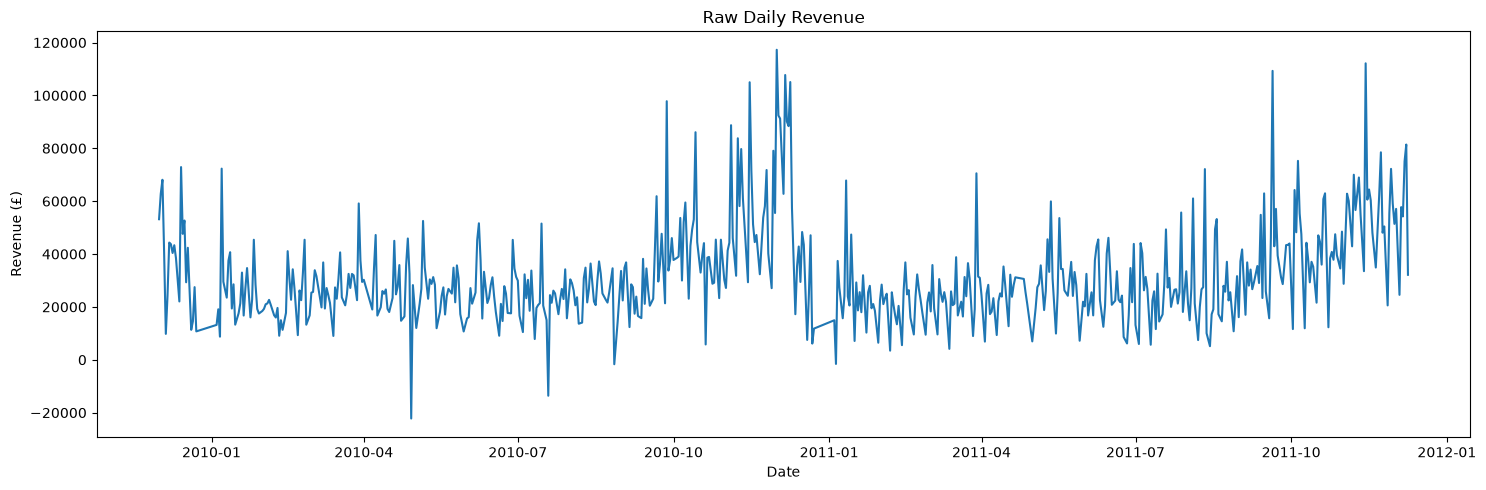

In [33]:
#Plot Daily Raw Revenue
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    daily_raw_revenue[
        "invoice_day"
    ],
    daily_raw_revenue[
        "revenue"
    ],
)

plt.title(
    "Raw Daily Revenue"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Revenue (£)"
)

plt.tight_layout()

plt.show()

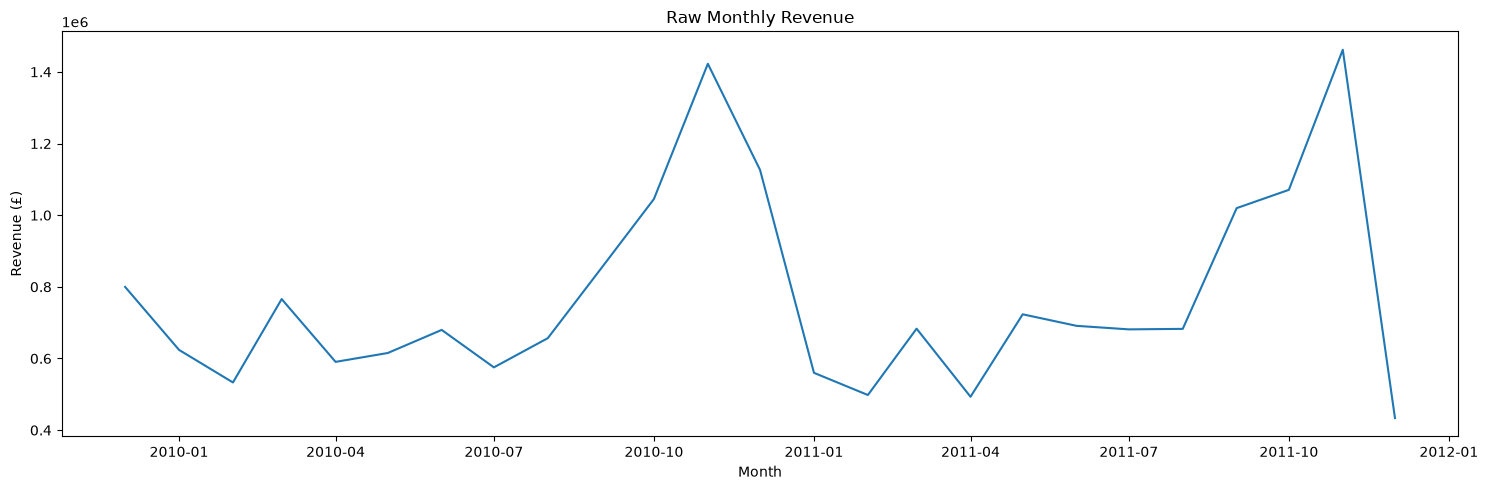

In [34]:
#Monthly raw revenue
monthly_raw_revenue = (
    working_df
    .set_index(
        "invoice_date"
    )["line_revenue"]
    .resample("MS")
    .sum()
    .reset_index()
)

#plot
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    monthly_raw_revenue[
        "invoice_date"
    ],
    monthly_raw_revenue[
        "line_revenue"
    ],
)

plt.title(
    "Raw Monthly Revenue"
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Revenue (£)"
)

plt.tight_layout()

plt.show()

In [35]:
#Check Missing Calendar Days
actual_days = (
    pd.DatetimeIndex(
        daily_raw_revenue[
            "invoice_day"
        ]
    )
)
#Full range
full_range = pd.date_range(
    start=min_date.floor("D"),
    end=max_date.floor("D"),
    freq="D",
)

missing_days = (
    full_range
    .difference(
        actual_days
    )
)

print(
    f"Missing calendar days: "
    f"{len(missing_days):,}"
)
missing_days[:30]

Missing calendar days: 135


DatetimeIndex(['2009-12-12', '2009-12-19', '2009-12-24', '2009-12-25',
               '2009-12-26', '2009-12-27', '2009-12-28', '2009-12-29',
               '2009-12-30', '2009-12-31', '2010-01-01', '2010-01-02',
               '2010-01-03', '2010-01-09', '2010-01-16', '2010-01-23',
               '2010-01-30', '2010-02-06', '2010-02-13', '2010-02-20',
               '2010-02-27', '2010-03-06', '2010-03-13', '2010-03-20',
               '2010-03-27', '2010-04-02', '2010-04-03', '2010-04-04',
               '2010-04-05', '2010-04-10'],
              dtype='datetime64[us]', freq=None)

In [36]:
#Data Quality Report
quality_summary = {
    "rows":
        len(working_df),

    "columns":
        len(working_df.columns),

    "missing_values":
        int(
            working_df
            .isna()
            .sum()
            .sum()
        ),

    "duplicate_rows":
        int(
            working_df
            .duplicated()
            .sum()
        ),

    "cancelled_rows":
        int(
            working_df[
                "is_cancelled"
            ].sum()
        ),

    "negative_quantity":
        int(
            (
                working_df[
                    "quantity"
                ] < 0
            ).sum()
        ),

    "zero_quantity":
        int(
            (
                working_df[
                    "quantity"
                ] == 0
            ).sum()
        ),

    "negative_price":
        int(
            (
                working_df[
                    "unit_price"
                ] < 0
            ).sum()
        ),

    "zero_price":
        int(
            (
                working_df[
                    "unit_price"
                ] == 0
            ).sum()
        ),

    "negative_revenue":
        int(
            (
                working_df[
                    "line_revenue"
                ] < 0
            ).sum()
        ),
}

quality_summary

{'rows': 1067371,
 'columns': 12,
 'missing_values': 247389,
 'duplicate_rows': 12133,
 'cancelled_rows': 19494,
 'negative_quantity': 22950,
 'zero_quantity': 0,
 'negative_price': 5,
 'zero_price': 6202,
 'negative_revenue': 19498}

In [37]:
#create Data Quality DataFrame
quality_report = pd.DataFrame({
    "metric": [
        "Rows",
        "Missing values",
        "Duplicate rows",
        "Cancelled rows",
        "Negative quantity",
        "Zero quantity",
        "Negative unit price",
        "Zero unit price",
        "Negative revenue",
    ],

    "value": [
        len(working_df),

        working_df
        .isna()
        .sum()
        .sum(),

        working_df
        .duplicated()
        .sum(),

        working_df[
            "is_cancelled"
        ].sum(),

        (
            working_df[
                "quantity"
            ] < 0
        ).sum(),

        (
            working_df[
                "quantity"
            ] == 0
        ).sum(),

        (
            working_df[
                "unit_price"
            ] < 0
        ).sum(),

        (
            working_df[
                "unit_price"
            ] == 0
        ).sum(),

        (
            working_df[
                "line_revenue"
            ] < 0
        ).sum(),
    ],
})

quality_report

,metric,value
0,Rows,1067371
1,Missing values,247389
2,Duplicate rows,12133
3,Cancelled rows,19494
4,Negative quantity,22950
5,Zero quantity,0
6,Negative unit price,5
7,Zero unit price,6202
8,Negative revenue,19498


In [38]:
#Forecasting Suitability
checks = {
    "dataset_not_empty":
        not working_df.empty,

    "invoice_date_exists":
        "invoice_date"
        in working_df.columns,

    "quantity_exists":
        "quantity"
        in working_df.columns,

    "unit_price_exists":
        "unit_price"
        in working_df.columns,

    "valid_dates_exist":
        working_df[
            "invoice_date"
        ].notna().any(),

    "historical_data_over_one_year":
        history_days >= 365,

    "enough_transactions":
        len(
            working_df
        ) >= 100_000,
}

for check, passed in checks.items():

    status = (
        "PASS"
        if passed
        else "FAIL"
    )

    print(
        f"{status:<6} {check}"
    )

PASS   dataset_not_empty
PASS   invoice_date_exists
PASS   quantity_exists
PASS   unit_price_exists
PASS   valid_dates_exist
PASS   historical_data_over_one_year
PASS   enough_transactions


In [39]:
#Business Summary
print(
    "=" * 65
)

print(
    "ONLINE RETAIL II — DATASET SUMMARY"
)

print(
    "=" * 65
)

print(
    f"Transaction rows : "
    f"{len(working_df):,}"
)

print(
    f"Date range       : "
    f"{min_date.date()} "
    f"→ "
    f"{max_date.date()}"
)

print(
    f"Historical years : "
    f"{history_years:.2f}"
)

print(
    f"Unique invoices  : "
    f"{working_df['invoice_no'].nunique():,}"
)

print(
    f"Products         : "
    f"{working_df['stock_code'].nunique():,}"
)

print(
    f"Customers        : "
    f"{working_df['customer_id'].nunique():,}"
)

print(
    f"Countries        : "
    f"{working_df['country'].nunique():,}"
)

print(
    f"Cancelled rows   : "
    f"{working_df['is_cancelled'].sum():,}"
)

ONLINE RETAIL II — DATASET SUMMARY
Transaction rows : 1,067,371
Date range       : 2009-12-01 → 2011-12-09
Historical years : 2.02
Unique invoices  : 53,628
Products         : 5,305
Customers        : 5,942
Countries        : 43
Cancelled rows   : 19,494


In [40]:
cancel_summary = (
    working_df
    .groupby("is_cancelled")["line_revenue"]
    .agg(
        rows="count",
        total_revenue="sum",
        average_revenue="mean",
        minimum_revenue="min"
    )
)

display(cancel_summary)

,rows,total_revenue,average_revenue,minimum_revenue
is_cancelled,,,,
False,1047877,"20,813,918.43",19.86,"-53,594.36"
True,19494,"-1,526,667.86",-78.31,"-168,469.60"


## Conclusion

The UCI Online Retail II dataset contains more than one million
transaction-level records covering approximately two years of
online retail activity.

The dataset provides the core variables required to construct
a sales forecasting time series:

- Invoice date and time
- Quantity
- Unit price
- Product
- Customer
- Country

Revenue is not directly available and will be derived from:

Revenue = Quantity × Unit Price

Several important data-quality and business issues were identified:

- Cancelled invoices
- Negative quantities
- Zero or invalid prices
- Missing customer identifiers
- Potential duplicate records
- Missing calendar dates
- Negative transaction revenue

These issues must be addressed before constructing the final
daily sales series.

The dataset is suitable for developing a 30/60/90-day revenue
forecasting pipeline after preprocessing.